## formative3_part1 (1)

<!-- merged from: formative3_part1 (1).ipynb (Jupy Tools) -->

# Formative 3, Part 1: Expectation-Maximization on Galton Heights

**Goal:** treat heights of two populations (mothers and sons) as one *unlabeled* pile and recover the two hidden Gaussians with EM written from scratch (NumPy only, no sklearn).

**Flow of this notebook:** data, the math, the code, the required tracking table, the fit, why a global mean split is the wrong tool, then the live posterior demo.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Settings you can change in one place ----
CSV_PATH     = "GaltonFamilies.csv"
PARENT       = "mother"             # "mother" or "father"
CHILD_GROUP  = "male"               # "male", "female" or None for all children
NAMES        = ("Child", "Parent")  # use ("Child", "Basketball Player") if the coach uses that wording
TEST_HEIGHT  = 66.0                 # the coach's number goes here
USE_INPUT    = False                # True means the notebook asks you to type the coach's height

# Fail early with a clear message if the dataset is missing
assert os.path.exists(CSV_PATH), f"Put {CSV_PATH} in the same folder as this notebook."

In [ ]:
# EM implementation
def load_heights(csv_path, parent="mother", child_group="male"):
    """Return (pooled heights, parent heights, child heights).

    The pooled array is the ONLY thing the model sees: labels are never passed on.
    The separate parent and child arrays are kept just to evaluate the result.
    """
    df = pd.read_csv(csv_path)
    # Galton has one row per child, so a mother repeats once per child.
    # Keeping one row per family so each mother is counted exactly once.
    parents = df.drop_duplicates("family")[parent].to_numpy(float)
    # Restricting to one gender so the child group is a single bell curve, not two bumps.
    kids = df if child_group is None else df[df["gender"] == child_group]
    children = kids["childHeight"].to_numpy(float)
    return np.concatenate([parents, children]), parents, children


def gaussian_pdf(x, mu, var):
    """Normal density N(x | mu, var). Works on a single number or a whole array."""
    return np.exp(-((x - mu) ** 2) / (2 * var)) / np.sqrt(2 * np.pi * var)


def weighted_components(x, mu, var, pi):
    """pi_k * N(x | mu_k, var_k) for every component k.

    Returns an array of shape (len(x), K). The likelihood, the E-step and the
    classifier all need this same quantity, so it lives in one place (DRY).
    """
    return np.column_stack([pi[k] * gaussian_pdf(x, mu[k], var[k]) for k in range(len(mu))])


def log_likelihood(x, mu, var, pi):
    """l = sum_i log( sum_k pi_k N(x_i | mu_k, var_k) ). EM never makes this go down."""
    mixture_density = weighted_components(x, mu, var, pi).sum(axis=1)  # p(x_i) for each point
    return float(np.sum(np.log(mixture_density)))


def e_step(x, mu, var, pi):
    """Expectation step: responsibilities r_ik = P(component k | x_i), by Bayes' theorem."""
    w = weighted_components(x, mu, var, pi)       # numerator: prior * likelihood
    return w / w.sum(axis=1, keepdims=True)       # divide by the evidence so each row sums to 1


def m_step(x, r):
    """Maximization step: re-estimate parameters using responsibilities as weights."""
    nk = r.sum(axis=0)                                        # effective number of points per component
    mu = (r * x[:, None]).sum(axis=0) / nk                    # weighted mean
    var = (r * (x[:, None] - mu) ** 2).sum(axis=0) / nk       # weighted variance around the new mean
    pi = nk / len(x)                                          # mixing weight = share of total responsibility
    return mu, var, pi


def init_params(x, children_is_taller):
    """Data driven start: means at the 25th and 75th percentiles, pooled variance, equal weights.

    Component 1 is always the Child component, so if children are taller it gets the high mean.
    """
    lo, hi = np.percentile(x, [25, 75])
    mu = np.array([hi, lo]) if children_is_taller else np.array([lo, hi])
    var = np.array([x.var(), x.var()])
    pi = np.array([0.5, 0.5])
    return mu, var, pi


def fit_em(x, children_is_taller, tol=1e-6, max_iter=1000):
    """Run EM until the log-likelihood changes by less than tol.

    history rows: (iteration, mu1, mu2, var1, var2, pi1, pi2, log-likelihood).
    Iteration 0 is the initial state before any update.
    """
    mu, var, pi = init_params(x, children_is_taller)
    ll = log_likelihood(x, mu, var, pi)
    history = [(0, *mu, *var, *pi, ll)]
    for i in range(1, max_iter + 1):
        r = e_step(x, mu, var, pi)                  # E-step with the current parameters
        mu, var, pi = m_step(x, r)                  # M-step gives the new parameters
        new_ll = log_likelihood(x, mu, var, pi)
        history.append((i, *mu, *var, *pi, new_ll))
        if abs(new_ll - ll) < tol:                  # convergence: the fit has stopped improving
            break
        ll = new_ll
    return mu, var, pi, history


def tracking_table(history, rows=(0, 1, 2)):
    """The required table: initial state plus the first two iterations."""
    cols = ["Iteration", "mu1 (Children)", "mu2 (Parent)", "var1", "var2", "pi1", "pi2", "Log-Likelihood"]
    df = pd.DataFrame(history, columns=cols)
    return df[df["Iteration"].isin(rows)].round(4).reset_index(drop=True)


def classify(height, mu, var, pi, names=("Child", "Parent")):
    """Exact posterior P(group | height) for one height, by Bayes' theorem."""
    w = weighted_components(np.array([height], float), mu, var, pi)[0]
    return dict(zip(names, (w / w.sum()).tolist()))


## 1. Data

Each Galton row is one *child*, so a mother appears once per child. Counting her every time would repeat the same height up to 15 times and give the parent group far more weight than it deserves. We therefore keep **one row per family** for the parent.

We compare mothers with **sons** only. Pooling sons and daughters makes the child group itself bimodal (two bumps), which breaks the "one Gaussian per group" assumption and EM then splits the pooled data into tall and short people instead of children and parents.


n parents = 205, n children = 481, pooled n = 686
mean parents = 64.00, mean children = 69.23


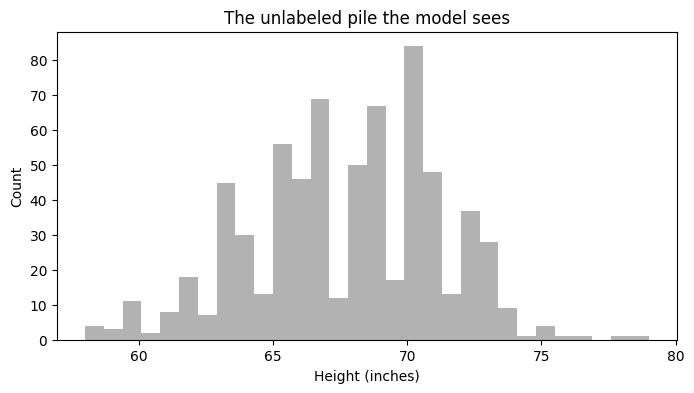

In [ ]:
# Load the data. x is the unlabeled pile; parents and children are kept only for scoring later.
x, parents, children = load_heights(CSV_PATH, PARENT, CHILD_GROUP)

# Children are taller than parents in this setup, which decides which component we call "Child"
taller = children.mean() > parents.mean()
print(f"n parents = {len(parents)}, n children = {len(children)}, pooled n = {len(x)}")
print(f"mean parents = {parents.mean():.2f}, mean children = {children.mean():.2f}")

# Histogram of what the model actually sees: one pile, no labels
plt.figure(figsize=(8, 4))
plt.hist(x, bins=30, color="gray", alpha=0.6)
plt.xlabel("Height (inches)"); plt.ylabel("Count"); plt.title("The unlabeled pile the model sees")
plt.show()

## 2. The math

Model: each height comes from one of two Gaussians, chosen with mixing weights $\pi_1,\pi_2$ (they sum to 1).

$$p(x)=\sum_{k=1}^{2}\pi_k\,\mathcal N(x\mid\mu_k,\sigma_k^2)$$

**Initialization.** Means start at the 25th and 75th percentiles of the pooled data, both variances start at the pooled variance, and $\pi_1=\pi_2=0.5$. Starting from data driven values avoids the empty component problem that extreme starting points can cause.

**E-step (Bayes' theorem).** For every point, the responsibility of component $k$ is its posterior probability:

$$r_{ik}=\frac{\pi_k\,\mathcal N(x_i\mid\mu_k,\sigma_k^2)}{\sum_j \pi_j\,\mathcal N(x_i\mid\mu_j,\sigma_j^2)}$$

**M-step.** Re-estimate parameters using the responsibilities as weights, with $N_k=\sum_i r_{ik}$:

$$\mu_k=\frac{\sum_i r_{ik}x_i}{N_k},\qquad \sigma_k^2=\frac{\sum_i r_{ik}(x_i-\mu_k)^2}{N_k},\qquad \pi_k=\frac{N_k}{N}$$

**Log-likelihood and stopping.** After each update we compute

$$\ell=\sum_i\log\sum_k \pi_k\,\mathcal N(x_i\mid\mu_k,\sigma_k^2)$$

EM never decreases $\ell$. We stop when the change in $\ell$ is below $10^{-6}$, meaning another iteration would not change the fit.

## 3. Run EM and show the required tracking table (iterations 0, 1, 2)

In [ ]:
# Fit the model on the pooled heights
mu, var, pi, hist = fit_em(x, children_is_taller=taller)

# Required tracking table: iteration 0 (initial state), 1 and 2
print(tracking_table(hist).to_string(index=False))
print(f"\nConverged after {hist[-1][0]} iterations")
print(f"Final: mu = {mu.round(3)}, var = {var.round(3)}, pi = {pi.round(3)}")

 Iteration  mu1 (Children)  mu2 (Parent)    var1    var2    pi1    pi2  Log-Likelihood
         0         70.2000       65.0000 12.1720 12.1720 0.5000 0.5000      -1861.4779
         1         69.5172       65.7391  7.6412  9.6136 0.5112 0.4888      -1825.3628
         2         69.5443       65.6961  7.1496  9.8663 0.5131 0.4869      -1824.6039

Converged after 414 iterations
Final: mu = [69.956 65.139], var = [5.395 7.488], pi = [0.526 0.474]


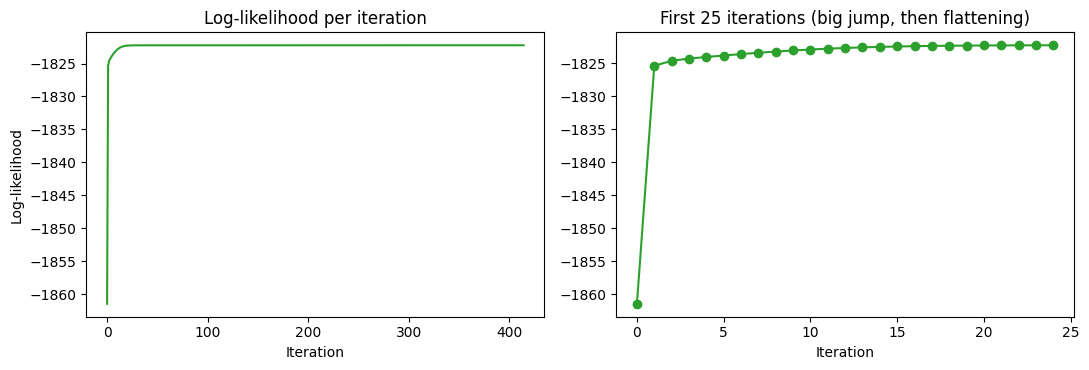

In [ ]:
# Log-likelihood is the last column of every history row
ll_series = [h[-1] for h in hist]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(ll_series, color="tab:green")                  # whole run
ax[0].set_title("Log-likelihood per iteration")
ax[0].set_xlabel("Iteration"); ax[0].set_ylabel("Log-likelihood")
ax[1].plot(range(25), ll_series[:25], marker="o", color="tab:green")   # zoom on the first 25 steps
ax[1].set_title("First 25 iterations (big jump, then flattening)"); ax[1].set_xlabel("Iteration")
plt.tight_layout(); plt.show()

**How to read it.** Iteration 0 is the data driven start. The log-likelihood rises at every step and the curve flattens, which is exactly the convergence signal: once it changes by less than $10^{-6}$ the parameters have stopped moving.

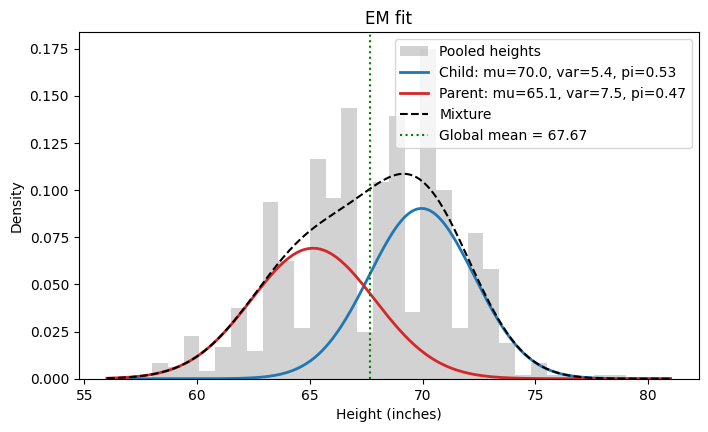

In [ ]:
def plot_fit(x, mu, var, pi, names=NAMES):
    """Histogram of the pooled data with the two learned weighted Gaussians and their sum."""
    grid = np.linspace(x.min() - 2, x.max() + 2, 400)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(x, bins=30, density=True, alpha=0.35, color="gray", label="Pooled heights")
    for k, c in zip(range(2), ("tab:blue", "tab:red")):
        # Each curve is pi_k * N(x | mu_k, var_k), so its area equals the mixing weight
        ax.plot(grid, pi[k] * gaussian_pdf(grid, mu[k], var[k]), color=c, lw=2,
                label=f"{names[k]}: mu={mu[k]:.1f}, var={var[k]:.1f}, pi={pi[k]:.2f}")
    ax.plot(grid, weighted_components(grid, mu, var, pi).sum(axis=1), "k--", label="Mixture")
    ax.axvline(x.mean(), color="green", ls=":", label=f"Global mean = {x.mean():.2f}")
    ax.set_xlabel("Height (inches)"); ax.set_ylabel("Density"); ax.set_title("EM fit"); ax.legend()
    plt.show()

plot_fit(x, mu, var, pi)

## 4. Should we just split at the global mean?

**No.** Cutting at the pooled mean and averaging each pile is a hard assignment, and it fails for three reasons:

1. **It ignores overlap.** Mothers and sons overlap between roughly 64 and 70 inches. A hard cut puts every point on one side with certainty, so a 67 inch person right next to the line is called a parent or a child with the same confidence as a 55 inch or 78 inch person.
2. **Its pile means are truncated estimates.** Each pile is a sliced piece of a bell curve (the lower pile has lost its upper tail, the upper pile its lower tail), so averaging a pile is biased in principle. EM fits all points with probability weights and no hard truncation. In practice the improvement depends on the data, so we print the numbers rather than assume them.
3. **It gives no uncertainty and learns nothing else.** EM also estimates the variances and the mixing proportions and reports a posterior probability per point (a soft assignment). A mean split can only say left or right.

The cell below measures this on our data instead of just claiming it.

In [ ]:
# True labels are used ONLY here, to score the two methods. The model never saw them.
truth_child = np.concatenate([np.zeros(len(parents), bool), np.ones(len(children), bool)])

# Method A: hard split at the global mean. The taller side is called "child".
cut = x.mean()
pred_child_mean = (x > cut) if taller else (x <= cut)
acc_mean = np.mean(pred_child_mean == truth_child)
hi_pile, lo_pile = x[x > cut], x[x <= cut]          # the two piles and their means

# Method B: EM. Take the component with the larger responsibility (threshold 0.5), for scoring only.
r = e_step(x, mu, var, pi)
acc_em = np.mean((r[:, 0] > 0.5) == truth_child)

print(f"Global mean cut: {cut:.2f}")
print(f"Pile means from the cut: {hi_pile.mean():.2f} and {lo_pile.mean():.2f}")
print(f"True group means:        {children.mean():.2f} (children) and {parents.mean():.2f} (parents)")
print(f"EM learned means:        {mu[0]:.2f} and {mu[1]:.2f}\n")
print(f"Accuracy, global mean split: {acc_mean:.3f}")
print(f"Accuracy, EM (threshold 0.5): {acc_em:.3f}")

# How many points is EM unsure about? The hard split labels all of them with full certainty.
uncertain = np.sum(np.max(r, axis=1) < 0.8)
print(f"\n{uncertain} of {len(x)} points ({uncertain/len(x):.0%}) have EM confidence below 80%.")
print("A mean split would label all of them with full certainty.")

Global mean cut: 67.67
Pile means from the cut: 70.35 and 64.58
True group means:        69.23 (children) and 64.00 (parents)
EM learned means:        69.96 and 65.14

Accuracy, global mean split: 0.805
Accuracy, EM (threshold 0.5): 0.813

248 of 686 points (36%) have EM confidence below 80%.
A mean split would label all of them with full certainty.


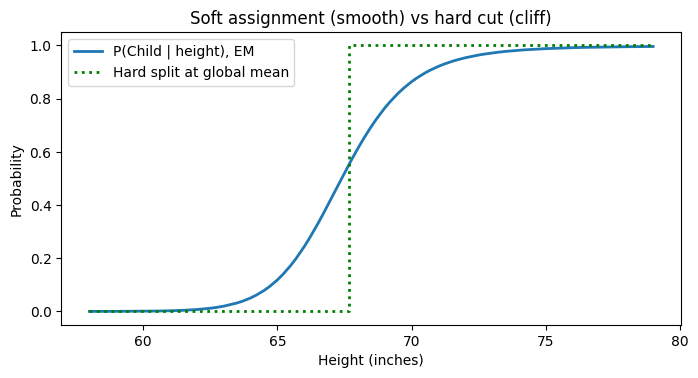

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.8))
order = np.argsort(x)                                # sort so the curve is drawn left to right
ax.plot(x[order], r[order, 0], color="tab:blue", lw=2, label=f"P({NAMES[0]} | height), EM")
# The hard split is a cliff: probability jumps from 0 to 1 at the global mean
ax.step([x.min(), cut, x.max()], [0 if taller else 1, 1 if taller else 0, 1 if taller else 0],
        where="post", color="green", ls=":", lw=2, label="Hard split at global mean")
ax.set_xlabel("Height (inches)"); ax.set_ylabel("Probability"); ax.legend()
ax.set_title("Soft assignment (smooth) vs hard cut (cliff)")
plt.show()

**What the numbers say.** Forced into a yes or no decision, EM and the mean split score about the same, because two reasonably separated groups are already decently split by one threshold. EM's advantage is not a jump in accuracy. It returns a probability for every point (a large share of heights sit in the overlap and are genuinely uncertain), it estimates variances and mixing weights, and it needs no arbitrary cut. Also note honestly that neither method recovers the true group means perfectly, because the two groups overlap heavily.

## 5. Live classification: posterior probabilities for the coach's height

Bayes' theorem with the learned parameters:
$P(\text{Child}\mid h)=\dfrac{\pi_1\mathcal N(h\mid\mu_1,\sigma_1^2)}{\pi_1\mathcal N(h\mid\mu_1,\sigma_1^2)+\pi_2\mathcal N(h\mid\mu_2,\sigma_2^2)}$

Height = 66.0 inches
  P(Child) = 0.2434  (24.34%)
  P(Parent) = 0.7566  (75.66%)


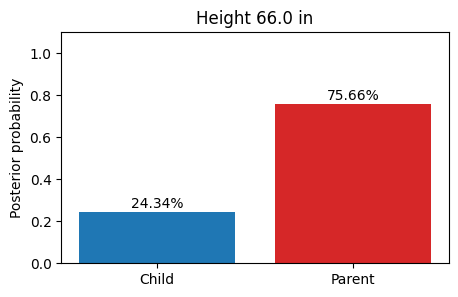

In [ ]:
def show_posterior(height, mu, var, pi, names=NAMES):
    """Print and plot the exact posterior probabilities for one height."""
    post = classify(height, mu, var, pi, names)      # classify() comes from the EM cell above
    print(f"Height = {height} inches")
    for k, v in post.items():
        print(f"  P({k}) = {v:.4f}  ({v*100:.2f}%)")
    fig, ax = plt.subplots(figsize=(5, 3))
    bars = ax.bar(list(post), list(post.values()), color=["tab:blue", "tab:red"])
    ax.set_ylim(0, 1.1); ax.set_ylabel("Posterior probability"); ax.set_title(f"Height {height} in")
    for b in bars:                                   # write the percentage above each bar
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02, f"{b.get_height():.2%}", ha="center")
    plt.show()
    return post

# Enter number: typed live for demo in presentation if USE_INPUT is True, otherwise TEST_HEIGHT from the settings cell
height = float(input("Coach's height (inches): ")) if USE_INPUT else TEST_HEIGHT
_ = show_posterior(height, mu, var, pi)

### Run it for a spread of heights

Showing a few values makes the soft assignment visible: short heights are clearly one group, tall heights the other, and heights near the overlap split the probability.

In [ ]:
# A spread of heights shows the soft assignment: certain at the extremes, split in the overlap
rows = [{"Height": h, **{f"P({n})": round(p, 4) for n, p in classify(h, mu, var, pi).items()}}
        for h in (58, 62, 64, 66, 67, 68, 70, 72, 76)]
pd.DataFrame(rows)

,Height,P(Child),P(Parent)
0,58,0.0001,0.9999
1,62,0.0071,0.9929
2,64,0.0505,0.9495
3,66,0.2434,0.7566
4,67,0.4226,0.5774
5,68,0.6126,0.3874
6,70,0.8634,0.1366
7,72,0.9536,0.0464
8,76,0.9915,0.0085


## 6. Sanity checks (these should all pass)

In [ ]:
ll_vals = np.array([h[-1] for h in hist])
assert np.all(np.diff(ll_vals) > -1e-9), "log-likelihood must never decrease"
assert abs(pi.sum() - 1) < 1e-9, "mixing weights must sum to 1"
assert np.allclose(e_step(x, mu, var, pi).sum(axis=1), 1), "responsibilities must sum to 1 per point"
assert abs(sum(classify(TEST_HEIGHT, mu, var, pi).values()) - 1) < 1e-9, "posteriors must sum to 1"
print("All checks passed.")

All checks passed.


## Part_2_Bayesian_Probability (1)

<!-- merged from: Part_2_Bayesian_Probability (1).ipynb (Jupy Tools) -->

# Bayesian Probability:

[Link to GitHub Repository](https://github.com/L-nsamba/group-1-formative-3-probability-bayes-gradient-descent.git)

## 1. Data handling

### Dataset setup

Avoids repeated upload into colab filesysytem

In [20]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

dataset_path = Path("IMDB Dataset.csv")
archive_path = Path("imdb-dataset.zip")
dataset_url = "https://www.kaggle.com/api/v1/datasets/download/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews"

if not dataset_path.is_file():
    print("Downloading the IMDB reviews dataset...")
    urlretrieve(dataset_url, archive_path)
    with ZipFile(archive_path) as archive:
        if "IMDB Dataset.csv" not in archive.namelist():
            raise FileNotFoundError("The downloaded archive does not contain IMDB Dataset.csv")
        archive.extract("IMDB Dataset.csv", path=".")

if not dataset_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {dataset_path.resolve()}")
print(f"Successfully prepared {dataset_path}!")

Successfully prepared IMDB Dataset.csv!


## Format dataset
 . We strip punctuations and paragraph breaks

 . Only count one instance of a word per review

In [21]:
import csv

reviews = []

with open("IMDB Dataset.csv", encoding="utf-8", newline="") as f:
    reader = csv.DictReader(f)
    for row in reader:
        text = row["review"].lower()
        text = text.replace("<br />", " ")
        # take out punctuation so "good!" counts as "good"
        for ch in ".,!?;:\"()-/*":
            text = text.replace(ch, " ")
        words = set(text.split())  # store in a set so each word counts only once per review
        reviews.append((words, row["sentiment"]))

print(f"Successfully loaded {len(reviews)} total reviews!")

Successfully loaded 50000 total reviews!


## 3. Keyword selection
4 Keywords that indicate positive sentiment: "favorite", "excellent", "wonderful", "masterpiece"

4 Keywords that indicate negative sentiment: "boring", "horrible", "worst", "sucks"

### 3.1 Why We Chose These Negative Keywords

We chose **horrible**, **boring**, **worst**, and **sucks** because they express negative judgment in different ways: a strong evaluation, a reaction to the experience, a comparison, and an informal criticism. This lets us test whether different kinds of negative wording are associated with negative review labels, rather than relying on four near-synonyms. We count exact word matches, so variations such as *sucked* are not included.

### 3.2 Why We Chose These Positive Keywords

We chose **favorite**, **excellent**, **wonderful**, and **masterpiece** to capture different ways reviewers express positive sentiment: personal preference, direct evaluation, enthusiasm, and praise for a film’s overall quality. This gives us a broader set of positive signals than four similar adjectives. Since we count exact word matches, related forms are not included.

## 4. Choice of conditional probability

For every selected keyword, we calculate `P(Negative | keyword)`.

In [22]:
negative_words = ["horrible", "boring", "worst", "sucks"]
positive_words = ["favorite", "excellent", "wonderful", "masterpiece"]
selected_words = positive_words + negative_words

## 5. Define useful variables

`total` is the number of reviews, and `total_negative_reviews` is the number labeled negative.

In [23]:
total = len(reviews)
total_negative_reviews = 0
for words, sentiment in reviews:
    if sentiment == "negative":
        total_negative_reviews = total_negative_reviews + 1

print("total reviews:", total)
print("negative reviews:", total_negative_reviews)

total reviews: 50000
negative reviews: 25000


## 6. Bayes' theorem implementation

The helper below applies `P(Negative | keyword) = P(keyword | Negative) * P(Negative) / P(keyword)`.

In [24]:
def bayes(prior, likelihood, evidence):
    return likelihood * prior / evidence

## 7. Calculate keyword probabilities

In [25]:
def negative_probability_for_keyword(word):
    with_word = 0        # reviews that have the word
    neg_with_word = 0    # negative reviews that have the word

    for words, sentiment in reviews:
        if word in words:
            with_word = with_word + 1
            if sentiment == "negative":
                neg_with_word = neg_with_word + 1

    if with_word == 0 or total_negative_reviews == 0:
        return None

    prior = total_negative_reviews / total                 # P(Negative)
    likelihood = neg_with_word / total_negative_reviews    # P(word | Negative)
    marginal = with_word / total                           # P(word)
    posterior = bayes(prior, likelihood, marginal)         # P(Negative | word)
    check = neg_with_word / with_word                      # direct check

    return {
        "word": word,
        "prior": prior,
        "likelihood": likelihood,
        "marginal": marginal,
        "posterior": posterior,
        "check": check,
        "total_appearances": with_word,
        "negative_appearances": neg_with_word
    }

## 8. Computation and presentation (table)

In [26]:
results = []

print("Bayesian probability results for selected keywords:")
print("| keyword | prior | likelihood | marginal | posterior | direct check |")
print("|---------|-------|------------|----------|-----------|--------------|")

for word in selected_words:
    result = negative_probability_for_keyword(word)

    if result is None:
        print(f"| {word} | word not found | | | | |")
        continue

    results.append(result)
    print(
        f"| {word} | {result['prior']:.4f} "
        f"| {result['likelihood']:.4f} "
        f"| {result['marginal']:.4f} "
        f"| {result['posterior']:.4f} "
        f"| {result['check']:.4f} |"
    )

Bayesian probability results for selected keywords:
| keyword | prior | likelihood | marginal | posterior | direct check |
|---------|-------|------------|----------|-----------|--------------|
| favorite | 0.5000 | 0.0208 | 0.0424 | 0.2455 | 0.2455 |
| excellent | 0.5000 | 0.0274 | 0.0710 | 0.1927 | 0.1927 |
| wonderful | 0.5000 | 0.0209 | 0.0555 | 0.1880 | 0.1880 |
| masterpiece | 0.5000 | 0.0130 | 0.0240 | 0.2700 | 0.2700 |
| horrible | 0.5000 | 0.0708 | 0.0419 | 0.8449 | 0.8449 |
| boring | 0.5000 | 0.0983 | 0.0610 | 0.8064 | 0.8064 |
| worst | 0.5000 | 0.1608 | 0.0886 | 0.9076 | 0.9076 |
| sucks | 0.5000 | 0.0190 | 0.0108 | 0.8764 | 0.8764 |


## 9. Visualization of Keyword Results

These charts show how each selected keyword updates the prior probability of a review being negative.

The second chart compares the likelihood P(keyword | Negative) with the posterior P(Negative | keyword); these are different probabilities.

This visualization uses Matplotlib; if it is not installed in your notebook environment, run `python -m pip install matplotlib`.

## 9.1 Prior-to-Posterior Update

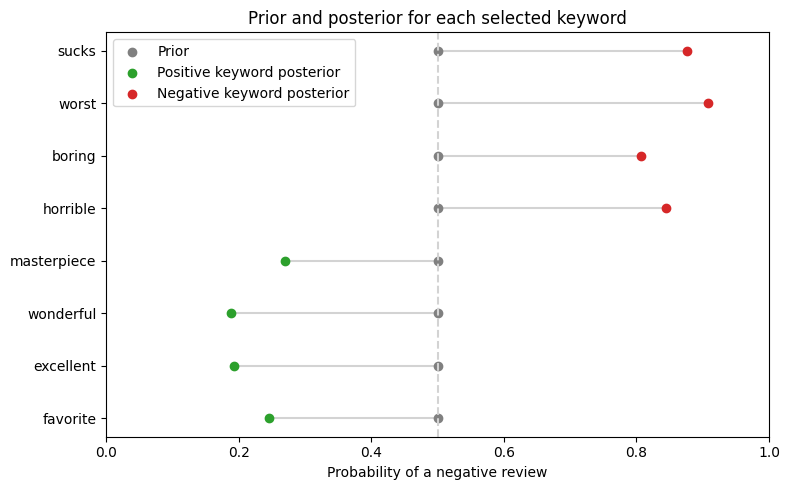

In [27]:
import matplotlib.pyplot as plt

positions = list(range(len(results)))
keywords = [result["word"] for result in results]
prior = results[0]["prior"] if results else 0

plt.figure(figsize=(8, 5))

for index, result in enumerate(results):
    plt.plot(
        [result["prior"], result["posterior"]],
        [index, index],
        color="lightgray",
        zorder=1,
    )
    plt.scatter(result["prior"], index, color="gray", zorder=2)

    if result["word"] in positive_words:
        plt.scatter(result["posterior"], index, color="tab:green", zorder=2)
    else:
        plt.scatter(result["posterior"], index, color="tab:red", zorder=2)

plt.yticks(positions, keywords)
plt.xlim(0, 1)
plt.axvline(prior, linestyle="--", color="lightgray")
plt.xlabel("Probability of a negative review")
plt.title("Prior and posterior for each selected keyword")
plt.scatter([], [], color="gray", label="Prior")
plt.scatter([], [], color="tab:green", label="Positive keyword posterior")
plt.scatter([], [], color="tab:red", label="Negative keyword posterior")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:** 
The gray dot shows the prior probability that a review is negative, before considering a keyword. 
The colored dot shows the posterior after observing that keyword. 
A dot to the right of the gray dot means the keyword raises the estimated probability of a negative review, while a dot to the left means it lowers the probability. Green represents positive keywords and red represents negative keywords. These are associations in this dataset, not proof that a keyword causes negative sentiment.

## 9.2 Likelihood Compared with Posterior

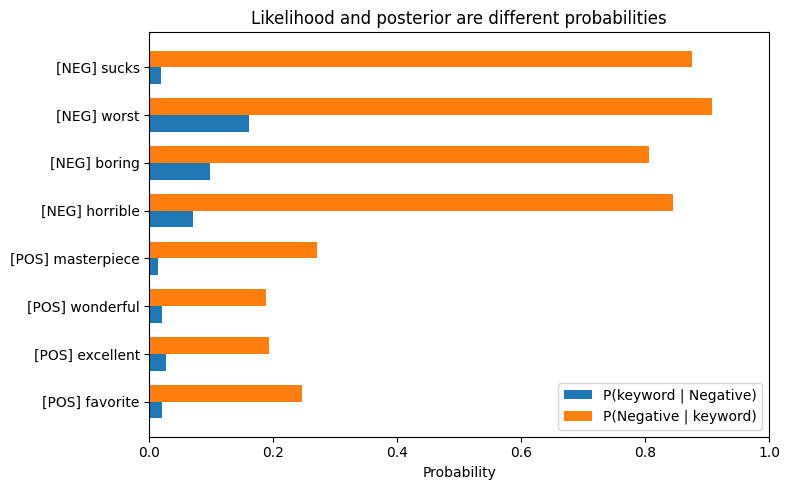

In [28]:
positions = list(range(len(results)))
keywords = [
    ("[POS] " if result["word"] in positive_words else "[NEG] ") + result["word"]
    for result in results
]
bar_height = 0.35

plt.figure(figsize=(8, 5))

plt.barh(
    [index - bar_height / 2 for index in positions],
    [result["likelihood"] for result in results],
    height=bar_height,
    label="P(keyword | Negative)",
)

plt.barh(
    [index + bar_height / 2 for index in positions],
    [result["posterior"] for result in results],
    height=bar_height,
    label="P(Negative | keyword)",
)

plt.yticks(positions, keywords)
plt.xlim(0, 1)
plt.xlabel("Probability")
plt.title("Likelihood and posterior are different probabilities")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:** 
The first bar shows how often a keyword appears among negative reviews. The second shows how likely a review is to be negative when that keyword appears. These probabilities answer different questions, so their values can differ substantially. The prior and the overall frequency of the keyword help explain that difference through Bayes’ theorem.
We expect positive keywords to have a lower posterior probability of a negative review, while negative keywords should have a higher posterior probability. The results help us see whether these expectations match the dataset.

## 10. Interpretation and limitations

- `prior` is the share of all reviews labeled negative.
- `likelihood` is the share of negative reviews containing the keyword, while `marginal` is the share of all reviews containing it.
- `posterior` is the probability of a negative label given that the review contains the keyword. The direct check computes the same quantity from review counts and helps verify the Bayes calculation.


- A keyword is only a simple signal, not a full sentiment model.
 Negation, sarcasm, and context can make even positive-associated words appear in negative reviews. e.g "not wonderful"
- Results describe this dataset and these selected keywords. Exact matching misses related word forms, and the preprocessing retains apostrophes. e.g "boring" misses "bored"

## Part_3_Gradient_Descent (1)

<!-- merged from: Part_3_Gradient_Descent (1).ipynb (Jupy Tools) -->

# [Link to GitHub Repository](https://github.com/L-nsamba/group-1-formative-3-probability-bayes-gradient-descent.git)

### Importing the relevant and accepted libraries that will be used during the subsequent calculations

In [78]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import approx_fprime

### Implementing the initial data provided in rubric in code form


In [79]:
# Input matrix
X = np.array([
    [1, 3],
    [4, 10]
], dtype=float)

# Actual output values
y = np.array([5, 6], dtype=float)

# Initial weights and bias
m = np.array([-1, 2], dtype=float)
b = 1.0

# Learning rate and number of iterations
alpha = 0.01
iterations = 3 # Corresponding to the number of team members

# Number of observations
n = len(y)

# Verifying the output
print("Input matrix X:\n", X)
print("Actual outputs y:", y)
print("Initial weights m:", m)
print("Initial bias b:", b)
print("Learning rate:", alpha)
print("Number of iterations:", iterations)

Input matrix X:
 [[ 1.  3.]
 [ 4. 10.]]
Actual outputs y: [5. 6.]
Initial weights m: [-1.  2.]
Initial bias b: 1.0
Learning rate: 0.01
Number of iterations: 3


### Creation of resusable functions for DRY and modular code

In [80]:
# Calculate predictions
def predict(X, m, b):
    return X @ m + b


# Calculate Mean Squared Error
def calculate_mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


# Calculate gradients using the chain rule
def calculate_gradients(X, y, m, b):
    errors = predict(X, m, b) - y
    n = len(y)

    dm1 = (2 / n) * np.sum(errors * X[:, 0])
    dm2 = (2 / n) * np.sum(errors * X[:, 1])
    db = (2 / n) * np.sum(errors)

    return np.array([dm1, dm2]), db

### Definition of the predictions and MSE calculations

In [81]:
# Predictions using one shared bias
y_hat = predict(X, m, b)

# Prediction errors
p_error = y_hat - y

# Mean Squared Error
mse = calculate_mse(y, y_hat)

print("Initial predictions:", y_hat)
print("Prediction errors:", p_error)
print(f"Initial MSE: {mse:.2f}")

Initial predictions: [ 6. 17.]
Prediction errors: [ 1. 11.]
Initial MSE: 61.00


### Definition of the MSE cost function

In [82]:
def cost_function(params, X, y):
  # Extracting the weights and bias from each parameter of the array
  m1 = params[0]
  m2 = params[1]
  b = params[2]


  # Calculation of the predictions
  # The same shared bias is added every observation
  y_hat = predict(X, np.array([m1, m2]), b)

  # Calculation and retrieving the value of the MSE
  return calculate_mse(y, y_hat)

# Combining the inital parameters into one array
params = np.array([m[0], m[1], b], dtype=float)
print("Initial cost:", cost_function(params, X, y))

Initial cost: 61.0


### Using SciPy to approximate the derivatives. This is what we use to get gradients for m1, m2 and b (dJ/dm1, dJ/dm2, dJ/db)

In [83]:
# Small step used for numerical differentiation
epsilon = 1e-8

# Approximating the gradient of the cost function
# where fprime is the derivative of f
def compute_derivative(func, params, *args, eps=epsilon):
    return approx_fprime(params, func, eps, *args)

# Passing the MSE cost function into the derivative function
gradient = compute_derivative(cost_function, params, X, y)

print(f"Gradient for m1: {gradient[0]:.2f}")
print(f"Gradient for m2: {gradient[1]:.2f}")
print(f"Gradient for b: {gradient[2]:.2f}")

Gradient for m1: 45.00
Gradient for m2: 113.00
Gradient for b: 12.00


### Calculating the gradients visibly with chain rule for the MSE cost function. This will give us the same answers as the previous cell where we made use of SciPy

In [84]:
# Calculating each gradient explicitly using the chain rule
gradients, db = calculate_gradients(X, y, m, b)
dm1, dm2 = gradients

p_error = predict(X, m, b) - y

print(f"Prediction errors: {p_error}")
print(f"Gradient for m1: {dm1:.2f}")
print(f"Gradient for m2: {dm2:.2f}")
print(f"Gradient for b: {db:.2f}")

Prediction errors: [ 1. 11.]
Gradient for m1: 45.00
Gradient for m2: 113.00
Gradient for b: 12.00


### Implementing the three gradient descent updates

In [85]:
# Storing the initial values for tracking
m_history = [m.copy()]
b_history = [b]

# Calculating the initial MSE
y_hat = predict(X, m, b)
mse_history = [calculate_mse(y, y_hat)]

for iteration in range(1, iterations + 1):

  # Calculating predictions and errors before the update
  y_hat = predict(X, m, b)
  errors = y_hat - y
  mse_before = calculate_mse(y, y_hat)

  # Calculating gradients using the chain rule
  gradients, db = calculate_gradients(X, y, m, b)
  dm1, dm2 = gradients

  # Verifying the manual gradients against SciPy
  current_params = np.array([m[0], m[1], b], dtype=float)
  scipy_grad = approx_fprime(
      current_params, cost_function, 1e-8, X, y
  )
  manual_grad = np.array([dm1, dm2, db])

  grads_match = np.allclose(
      scipy_grad, manual_grad, atol=1e-4 # where atol is the absolute tolerance
  )


  # Updating each parameter
  m[0] = m[0] - alpha * dm1
  m[1] = m[1] - alpha * dm2
  b = b - alpha * db

  # Calculating predictions and MSE after the update
  y_hat = predict(X, m, b)
  mse_after = calculate_mse(y, y_hat)

  # Storing the updated parameters
  m_history.append(m.copy())
  b_history.append(b)
  mse_history.append(mse_after)

  # Displaying the results with corrected indentation
  print(f"\nIteration {iteration}")
  print(f"MSE before update: {mse_before:.2f}")
  print(f"Gradient m1: {dm1:.2f}")
  print(f"Gradient m2: {dm2:.2f}")
  print(f"Gradient b: {db:.2f}")
  print(f"Updated m1: {m[0]:.4f}")
  print(f"Updated m2: {m[1]:.4f}")
  print(f"Updated b: {b:.4f}")
  print(f"Predictions: {y_hat}")
  print(f"MSE after update: {mse_after:.4f}")
  print(f"Manual and SciPy gradients match: {grads_match}")


Iteration 1
MSE before update: 61.00
Gradient m1: 45.00
Gradient m2: 113.00
Gradient b: 12.00
Updated m1: -1.4500
Updated m2: 0.8700
Updated b: 0.8800
Predictions: [2.04 3.78]
MSE after update: 6.8450
Manual and SciPy gradients match: True

Iteration 2
MSE before update: 6.85
Gradient m1: -11.84
Gradient m2: -31.08
Gradient b: -5.18
Updated m1: -1.3316
Updated m2: 1.1808
Updated b: 0.9318
Predictions: [3.1426 7.4134]
MSE after update: 2.7238
Manual and SciPy gradients match: True

Iteration 3
MSE before update: 2.72
Gradient m1: 3.80
Gradient m2: 8.56
Gradient b: -0.44
Updated m1: -1.3696
Updated m2: 1.0952
Updated b: 0.9362
Predictions: [2.852224 6.409812]
MSE after update: 2.3904
Manual and SciPy gradients match: True


### Verifying the final iteration (3) results for weight, bias, predictions and MSE

In [86]:
# Calculating predictions and MSE using the final parameters
final_y_hat = predict(X, m, b)
final_mse = calculate_mse(y, final_y_hat)

print("Final weights:", np.round(m, 2))
print(f"Final shared bias: {b:.2f}")
print("Final predictions:", np.round(final_y_hat, 2))
print(f"Final MSE: {final_mse:.2f}")

Final weights: [-1.37  1.1 ]
Final shared bias: 0.94
Final predictions: [2.85 6.41]
Final MSE: 2.39


### A plot showing how weights (m1, m2) and bias (b) change over iterations

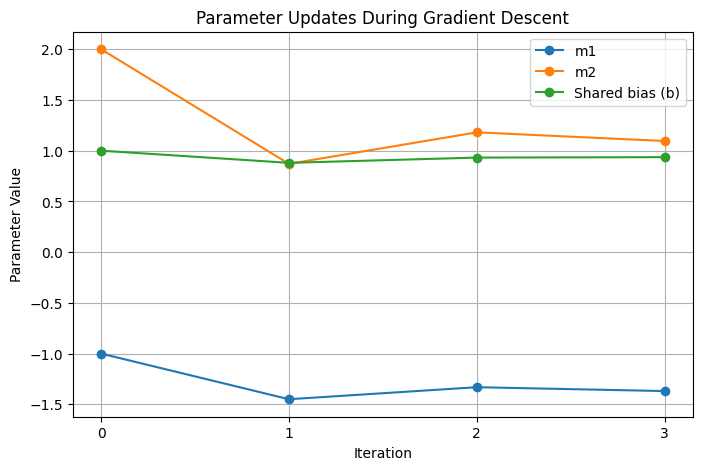

In [87]:
# Plotting parameter updates across iterations
iteration_numbers = range(len(m_history))

plt.figure(figsize=(8, 5))

# m1 plots
plt.plot(iteration_numbers, [m[0] for m in m_history], marker='o', label='m1')

# m2 plots
plt.plot(iteration_numbers, [m[1] for m in m_history], marker='o', label='m2')

# shared bias
plt.plot(iteration_numbers, b_history, marker='o', label='Shared bias (b)')

plt.xlabel('Iteration')
plt.ylabel('Parameter Value')
plt.title('Parameter Updates During Gradient Descent')
plt.xticks(iteration_numbers)
plt.legend()
plt.grid(True)
plt.show()

### Interpretation of the parameter updates during gradient descent

The plot shows how the weights and shared bias change over three gradient descent iterations. The weights adjust to reduce prediction errors, while the shared bias decreases from 1.00 to approximately 0.94. Together, these updates improve the model's predictions.

### A plot showing how the error (mse) changes over iterations.

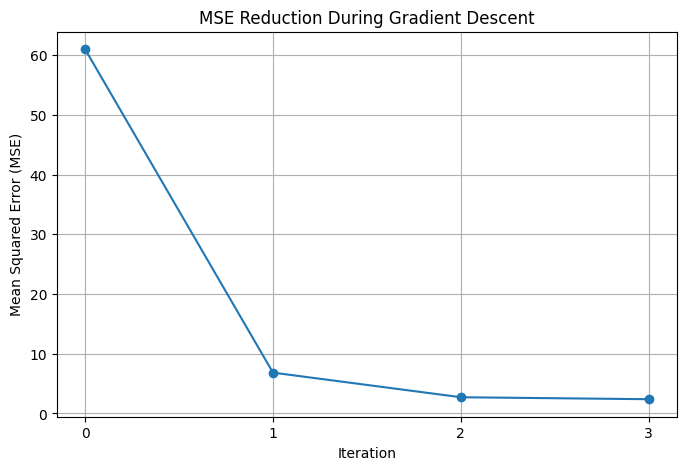

In [88]:
# Plotting MSE across iterations
iteration_numbers = range(len(mse_history))

plt.figure(figsize=(8, 5))

plt.plot(iteration_numbers, mse_history, marker='o')

plt.xlabel('Iteration')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MSE Reduction During Gradient Descent')
plt.xticks(iteration_numbers)
plt.grid(True)
plt.show()

### Interpretation of the mse reduction during gradient descent

The MSE decreases from 61.00 initially to approximately 6.85, 2.72, and 2.39 after the three updates. The largest improvement occurs in the first iteration. This shows that gradient descent is reducing the prediction error and improving the model's fit to the data.

### Conclusion

We implemented gradient descent to optimize the weights and a single shared bias for a linear regression model over three iterations. The MSE decreased from 61.00 to 2.39, indicating that the model's predictions improved with each update. The final weights were approximately [-1.37, 1.10], and the shared bias was 0.94, producing predictions of [2.85, 6.41]. The manual gradients were also verified against SciPy's numerical derivatives.